In [ ]:
import os
import numpy as np
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# -------------------------------------------------------------------------
# 1. Hardware, Config & Paths
# -------------------------------------------------------------------------
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Executing on hardware device: {DEVICE}")

# Updated parameters for higher resolution and optimal generalization
IMAGE_SIZE = (288, 288)
BATCH_SIZE = 16
ACCUMULATION_STEPS = 2   # 16 x 2 = effective batch size of 32
EPOCHS = 4
LEARNING_RATE = 2.5e-4
WEIGHT_DECAY = 1e-2
CHECKPOINT_PATH = "best_resnet18_288.pt"

TRAIN_LABELS_CSV = "train_labels.csv"
TRAIN_IMG_DIR = os.path.join("dataset_images", "train")

# -------------------------------------------------------------------------
# 2. Metadata, Class Encoding & Stratified Split
# -------------------------------------------------------------------------
train_df = pd.read_csv(TRAIN_LABELS_CSV, dtype={"image_id": str})
CLASSES = sorted(train_df["class"].unique())
CLASS_TO_IDX = {cls_name: i for i, cls_name in enumerate(CLASSES)}
IDX_TO_CLASS = {i: cls_name for cls_name, i in CLASS_TO_IDX.items()}
train_df["target"] = train_df["class"].map(CLASS_TO_IDX)

train_data, val_data = train_test_split(
    train_df,
    test_size=0.20,
    random_state=SEED,
    stratify=train_df["target"]
)
train_data = train_data.reset_index(drop=True)
val_data = val_data.reset_index(drop=True)

# -------------------------------------------------------------------------
# 3. Augmentations & Safe Dataset Class
# -------------------------------------------------------------------------
train_transforms = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.RandomHorizontalFlip(p=0.5), # Added horizontal flip for better generalization
    transforms.RandomRotation(degrees=10), # Added small random rotations to augment orientation variance
    transforms.ColorJitter(brightness=0.15, contrast=0.15), # Added color jitter for lighting variations
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], # Standard normalization for pre-trained models
                         std=[0.229, 0.224, 0.225])
])

val_transforms = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

class SafeDataset(Dataset):
    def __init__(self, df, img_dir, transform=None, is_test=False):
        self.df = df.reset_index(drop=True)
        self.img_dir = img_dir
        self.transform = transform
        self.is_test = is_test

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        raw_id = str(row["image_id"]).strip()
        base, ext = os.path.splitext(raw_id)
        ext = ext if ext else ".jpg"
        base_padded = base.zfill(5) if base.isdigit() else base

        filename = f"{base_padded}{ext}"
        path = os.path.join(self.img_dir, filename)
        if not os.path.exists(path):
            path = os.path.join(self.img_dir, f"{base}{ext}")

        image = Image.open(path).convert("RGB")
        if self.transform:
            image = self.transform(image)

        if self.is_test:
            return image, base_padded
        return image, torch.tensor(row["target"], dtype=torch.long)

num_workers = 2 if os.name != "nt" else 0
train_loader = DataLoader(SafeDataset(train_data, TRAIN_IMG_DIR, train_transforms),
                          batch_size=BATCH_SIZE, shuffle=True, pin_memory=True, num_workers=num_workers)
val_loader = DataLoader(SafeDataset(val_data, TRAIN_IMG_DIR, val_transforms),
                        batch_size=BATCH_SIZE, shuffle=False, pin_memory=True, num_workers=num_workers)

# -------------------------------------------------------------------------
# 4. Model Architecture & Optimization Setup
# -------------------------------------------------------------------------
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
in_features = model.fc.in_features
model.fc = nn.Sequential(
    nn.Dropout(p=0.3),
    nn.Linear(in_features, len(CLASSES))
)
model = model.to(DEVICE)

criterion = nn.CrossEntropyLoss(label_smoothing=0.05)
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
scaler = torch.amp.GradScaler(enabled=torch.cuda.is_available())

# -------------------------------------------------------------------------
# 5. Training Loop with Gradient Accumulation & Best-Model Checkpointing
# -------------------------------------------------------------------------
best_val_acc = 0.0
print(f"Beginning fine-tuning at {IMAGE_SIZE[0]}x{IMAGE_SIZE[1]} for {EPOCHS} epochs...\n")

for epoch in range(EPOCHS):
    model.train()
    running_loss, corrects, total = 0.0, 0, 0
    optimizer.zero_grad()

    train_bar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS} [Train]", leave=False)
    for batch_idx, (images, targets) in enumerate(train_bar):
        images, targets = images.to(DEVICE), targets.to(DEVICE)

        with torch.amp.autocast(device_type="cuda" if torch.cuda.is_available() else "cpu"):
            outputs = model(images)
            loss = criterion(outputs, targets)
            loss_scaled = loss / ACCUMULATION_STEPS

        scaler.scale(loss_scaled).backward()

        if (batch_idx + 1) % ACCUMULATION_STEPS == 0 or (batch_idx + 1) == len(train_loader):
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad()

        running_loss += loss.item() * targets.size(0)
        _, preds = outputs.max(1)
        corrects += (preds == targets).sum().item()
        total += targets.size(0)

    scheduler.step()
    train_acc = corrects / total
    train_loss = running_loss / total

    # Validation Phase
    model.eval()
    val_corrects, val_total, val_loss_running = 0, 0, 0.0
    with torch.no_grad():
        for images, targets in val_loader:
            images, targets = images.to(DEVICE), targets.to(DEVICE)
            with torch.amp.autocast(device_type="cuda" if torch.cuda.is_available() else "cpu"):
                outputs = model(images)
                loss = criterion(outputs, targets)

            val_loss_running += loss.item() * targets.size(0)
            _, preds = outputs.max(1)
            val_corrects += (preds == targets).sum().item()
            val_total += targets.size(0)

    val_acc = val_corrects / val_total
    val_loss = val_loss_running / val_total

    print(f"Epoch {epoch+1:02d} | Train Loss: {train_loss:.4f} Acc: {train_acc*100:.2f}% | "
          f"Val Loss: {val_loss:.4f} Acc: {val_acc*100:.2f}%")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), CHECKPOINT_PATH)
        print(f"  ⭐ Saved new best checkpoint: '{CHECKPOINT_PATH}' (Val Acc: {best_val_acc*100:.2f}%)")

print(f"\nTraining complete. Peak Validation Accuracy: {best_val_acc*100:.2f}%")

c:\Users\ivorc\Downloads\ENGE707\kaggle\ENGE707-kaggle-comp\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Executing on hardware device: cuda
Beginning fine-tuning at 288x288 for 4 epochs...



Epoch 01 | Train Loss: 0.3984 Acc: 95.93% | Val Loss: 0.3210 Acc: 98.51%
  ⭐ Saved new best checkpoint: 'best_resnet18_288.pt' (Val Acc: 98.51%)


Epoch 02 | Train Loss: 0.3224 Acc: 98.48% | Val Loss: 0.3056 Acc: 98.77%
  ⭐ Saved new best checkpoint: 'best_resnet18_288.pt' (Val Acc: 98.77%)


Epoch 03 | Train Loss: 0.3000 Acc: 99.13% | Val Loss: 0.2932 Acc: 99.17%
  ⭐ Saved new best checkpoint: 'best_resnet18_288.pt' (Val Acc: 99.17%)


Epoch 04 | Train Loss: 0.2842 Acc: 99.61% | Val Loss: 0.2818 Acc: 99.44%
  ⭐ Saved new best checkpoint: 'best_resnet18_288.pt' (Val Acc: 99.44%)

Training complete. Peak Validation Accuracy: 99.44%


In [2]:
import os
import pandas as pd
from tqdm.auto import tqdm
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import transforms

# -------------------------------------------------------------------------
# 1. Load Test Dataset at 288x288 Resolution
# -------------------------------------------------------------------------
SAMPLE_SUB_CSV = "sample_submission.csv"
TEST_IMG_DIR = os.path.join("dataset_images", "test")
OUTPUT_SUB_CSV = "submission.csv"

sample_sub = pd.read_csv(SAMPLE_SUB_CSV, dtype={"image_id": str})

test_transforms_highres = transforms.Compose([
    transforms.Resize((288, 288)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

test_loader_highres = DataLoader(
    SafeDataset(sample_sub, TEST_IMG_DIR, transform=test_transforms_highres, is_test=True),
    batch_size=16,
    shuffle=False,
    pin_memory=True,
    num_workers=2 if os.name != "nt" else 0
)

# -------------------------------------------------------------------------
# 2. Load Checkpoint and Run 6-View Multi-Scale TTA
# -------------------------------------------------------------------------
print(f"Loading '{CHECKPOINT_PATH}' for Multi-Scale TTA Inference...")
model.load_state_dict(torch.load(CHECKPOINT_PATH))
model.eval()

sub_ids = []
sub_preds = []

with torch.no_grad():
    for images, ids in tqdm(test_loader_highres, desc="Generating TTA Predictions"):
        images = images.to(DEVICE)

        with torch.amp.autocast(device_type="cuda" if torch.cuda.is_available() else "cpu"):
            # 1. Scale 1: Full Native Resolution (288 x 288)
            p_288 = F.softmax(model(images), dim=1)
            p_288_flip = F.softmax(model(torch.flip(images, dims=[3])), dim=1)

            # 2. Scale 2: Interpolated Mid Resolution (256 x 256)
            img_256 = F.interpolate(images, size=(256, 256), mode="bilinear", align_corners=False)
            p_256 = F.softmax(model(img_256), dim=1)
            p_256_flip = F.softmax(model(torch.flip(img_256, dims=[3])), dim=1)

            # 3. Scale 3: Standard Training Resolution (224 x 224)
            img_224 = F.interpolate(images, size=(224, 224), mode="bilinear", align_corners=False)
            p_224 = F.softmax(model(img_224), dim=1)
            p_224_flip = F.softmax(model(torch.flip(img_224, dims=[3])), dim=1)

            # Average all 6 multi-scale perspective vectors
            blended_probs = (
                p_288 + p_288_flip +
                p_256 + p_256_flip +
                p_224 + p_224_flip
            ) / 6.0

        _, preds = torch.max(blended_probs, dim=1)

        sub_ids.extend(ids)
        sub_preds.extend([IDX_TO_CLASS[p.item()] for p in preds])

# -------------------------------------------------------------------------
# 3. Format and Save Kaggle Submission
# -------------------------------------------------------------------------
submission_df = pd.DataFrame({
    "image_id": sub_ids,
    "class": sub_preds
})

submission_df.to_csv(OUTPUT_SUB_CSV, index=False)
print(f"\nGenerated '{OUTPUT_SUB_CSV}' successfully!")
print(f"Total rows verified: {len(submission_df)} (Matches test set: {len(submission_df) == len(sample_sub)})")
print("\nFirst 10 submission rows preview:")
print(submission_df.head(10))

Loading 'best_resnet18_288.pt' for Multi-Scale TTA Inference...


Generating TTA Predictions: 100%|██████████| 1841/1841 [04:38<00:00,  6.61it/s]


Generated 'submission.csv' successfully!
Total rows verified: 29443 (Matches test set: True)

First 10 submission rows preview:
  image_id     class
0    00001    DogEye
1    00002  DogMouth
2    00003   DogNose
3    00004   DogFace
4    00005  CatMouth
5    00006   DogFace
6    00007  CatMouth
7    00008    DogEye
8    00009    CatEye
9    00010   CatNose


In [3]:
import os
import pandas as pd
from tqdm.auto import tqdm
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import transforms

# -------------------------------------------------------------------------
# 1. Load Test Dataset at 288x288 Resolution
# -------------------------------------------------------------------------
SAMPLE_SUB_CSV = "sample_submission.csv"
TEST_IMG_DIR = os.path.join("dataset_images", "test")
OUTPUT_SUB_CSV = "submission.csv"

sample_sub = pd.read_csv(SAMPLE_SUB_CSV, dtype={"image_id": str})

test_transforms = transforms.Compose([
    transforms.Resize((288, 288)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

test_loader = DataLoader(
    SafeDataset(sample_sub, TEST_IMG_DIR, transform=test_transforms, is_test=True),
    batch_size=16,
    shuffle=False,
    pin_memory=True,
    num_workers=2 if os.name != "nt" else 0
)

# -------------------------------------------------------------------------
# 2. Load Checkpoint and Run Basic TTA (Original + Horizontal Flip)
# -------------------------------------------------------------------------
print(f"Loading '{CHECKPOINT_PATH}' for Basic TTA Inference...")
model.load_state_dict(torch.load(CHECKPOINT_PATH))
model.eval()

sub_ids = []
sub_preds = []

with torch.no_grad():
    for images, ids in tqdm(test_loader, desc="Generating Predictions (Basic TTA)"):
        images = images.to(DEVICE)

        with torch.amp.autocast(device_type="cuda" if torch.cuda.is_available() else "cpu"):
            # 1. Original image prediction
            outputs_orig = model(images)
            probs_orig = F.softmax(outputs_orig, dim=1)

            # 2. Horizontally flipped image prediction
            images_flipped = torch.flip(images, dims=[3])  # Flip across horizontal width axis
            outputs_flip = model(images_flipped)
            probs_flip = F.softmax(outputs_flip, dim=1)

            # 3. Average the two probability distributions
            avg_probs = (probs_orig + probs_flip) / 2.0

        _, preds = torch.max(avg_probs, dim=1)

        sub_ids.extend(ids)
        sub_preds.extend([IDX_TO_CLASS[p.item()] for p in preds])

# -------------------------------------------------------------------------
# 3. Format and Save Kaggle Submission
# -------------------------------------------------------------------------
submission_df = pd.DataFrame({
    "image_id": sub_ids,
    "class": sub_preds
})

submission_df.to_csv(OUTPUT_SUB_CSV, index=False)
print(f"\nGenerated '{OUTPUT_SUB_CSV}' successfully!")
print(f"Total rows verified: {len(submission_df)} (Matches test set: {len(submission_df) == len(sample_sub)})")
print("\nFirst 10 submission rows preview:")
print(submission_df.head(10))

Loading 'best_resnet18_288.pt' for Basic TTA Inference...


Generating Predictions (Basic TTA): 100%|██████████| 1841/1841 [03:13<00:00,  9.50it/s]


Generated 'submission.csv' successfully!
Total rows verified: 29443 (Matches test set: True)

First 10 submission rows preview:
  image_id     class
0    00001    DogEye
1    00002  DogMouth
2    00003   DogNose
3    00004   DogFace
4    00005  CatMouth
5    00006   DogFace
6    00007  CatMouth
7    00008    DogEye
8    00009    CatEye
9    00010   CatNose


Testing on device: cuda
Evaluating across 12,732 validation samples...


Testing best_resnet18_288.pt: 100%|██████████| 796/796 [01:16<00:00, 10.44it/s]



 Overall Validation Accuracy: 99.44%
 Correct Predictions: 12,661 / 12,732

Classification Report:
              precision    recall  f1-score   support

      CatEye     0.9978    0.9946    0.9962      2777
     CatFace     1.0000    0.9986    0.9993      1388
    CatMouth     0.9920    0.9856    0.9888      1388
     CatNose     0.9828    0.9870    0.9849      1389
      DogEye     0.9914    0.9965    0.9940      2316
     DogFace     0.9991    0.9991    0.9991      1158
    DogMouth     0.9965    0.9965    0.9965      1158
     DogNose     0.9957    0.9974    0.9965      1158

    accuracy                         0.9944     12732
   macro avg     0.9944    0.9944    0.9944     12732
weighted avg     0.9944    0.9944    0.9944     12732



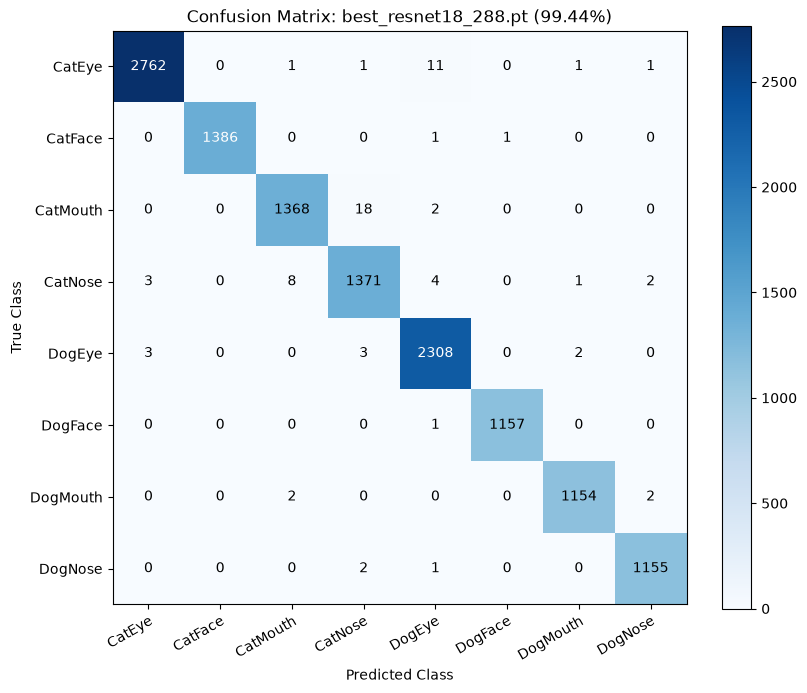

Confusion matrix saved to 'test_accuracy_confusion_matrix.png'


In [4]:
import os
import numpy as np
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# -------------------------------------------------------------------------
# 1. Config & File Paths
# -------------------------------------------------------------------------
SEED = 42
torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Testing on device: {DEVICE}")

CHECKPOINT_PATH = "best_resnet18_288.pt"
TRAIN_LABELS_CSV = "train_labels.csv"
TRAIN_IMG_DIR = os.path.join("dataset_images", "train")
IMAGE_SIZE = (288, 288)
BATCH_SIZE = 16

# -------------------------------------------------------------------------
# 2. Re-create the Exact Stratified Validation Split (20%)
# -------------------------------------------------------------------------
train_df = pd.read_csv(TRAIN_LABELS_CSV, dtype={"image_id": str})
CLASSES = sorted(train_df["class"].unique())
CLASS_TO_IDX = {cls_name: i for i, cls_name in enumerate(CLASSES)}
IDX_TO_CLASS = {i: cls_name for cls_name, i in CLASS_TO_IDX.items()}
train_df["target"] = train_df["class"].map(CLASS_TO_IDX)

_, val_data = train_test_split(
    train_df,
    test_size=0.20,
    random_state=SEED,
    stratify=train_df["target"]
)
val_data = val_data.reset_index(drop=True)
print(f"Evaluating across {len(val_data):,} validation samples...")

# -------------------------------------------------------------------------
# 3. Transforms and Safe Dataset Loader
# -------------------------------------------------------------------------
val_transforms = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

class SafeDataset(Dataset):
    def __init__(self, df, img_dir, transform=None):
        self.df = df.reset_index(drop=True)
        self.img_dir = img_dir
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        raw_id = str(row["image_id"]).strip()
        base, ext = os.path.splitext(raw_id)
        ext = ext if ext else ".jpg"
        base_padded = base.zfill(5) if base.isdigit() else base

        filename = f"{base_padded}{ext}"
        path = os.path.join(self.img_dir, filename)
        if not os.path.exists(path):
            path = os.path.join(self.img_dir, f"{base}{ext}")

        image = Image.open(path).convert("RGB")
        if self.transform:
            image = self.transform(image)

        return image, torch.tensor(row["target"], dtype=torch.long)

val_loader = DataLoader(
    SafeDataset(val_data, TRAIN_IMG_DIR, transform=val_transforms),
    batch_size=BATCH_SIZE,
    shuffle=False,
    pin_memory=torch.cuda.is_available(),
    num_workers=2 if os.name != "nt" else 0
)

# -------------------------------------------------------------------------
# 4. Load Model and Checkpoint Weights
# -------------------------------------------------------------------------
model = models.resnet18()
in_features = model.fc.in_features
model.fc = nn.Sequential(
    nn.Dropout(p=0.3),
    nn.Linear(in_features, len(CLASSES))
)
model.load_state_dict(torch.load(CHECKPOINT_PATH, map_location=DEVICE))
model = model.to(DEVICE)
model.eval()

# -------------------------------------------------------------------------
# 5. Validation Inference Loop
# -------------------------------------------------------------------------
all_preds = []
all_targets = []

with torch.no_grad():
    for images, targets in tqdm(val_loader, desc=f"Testing {CHECKPOINT_PATH}"):
        images = images.to(DEVICE)
        with torch.amp.autocast(device_type="cuda" if torch.cuda.is_available() else "cpu"):
            outputs = model(images)
        _, preds = torch.max(outputs, 1)
        
        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(targets.numpy())

all_preds = np.array(all_preds)
all_targets = np.array(all_targets)

# -------------------------------------------------------------------------
# 6. Evaluation Metrics & Confusion Matrix
# -------------------------------------------------------------------------
overall_acc = accuracy_score(all_targets, all_preds) * 100
print(f"\n==========================================")
print(f" Overall Validation Accuracy: {overall_acc:.2f}%")
print(f" Correct Predictions: {(all_preds == all_targets).sum():,} / {len(all_targets):,}")
print(f"==========================================\n")

print("Classification Report:")
print(classification_report(all_targets, all_preds, target_names=CLASSES, digits=4))

# Confusion Matrix Plot
cm = confusion_matrix(all_targets, all_preds)
fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(cm, interpolation="nearest", cmap=plt.cm.Blues)
ax.figure.colorbar(im, ax=ax)

ax.set(
    xticks=np.arange(cm.shape[1]),
    yticks=np.arange(cm.shape[0]),
    xticklabels=CLASSES,
    yticklabels=CLASSES,
    title=f"Confusion Matrix: best_resnet18_288.pt ({overall_acc:.2f}%)",
    ylabel="True Class",
    xlabel="Predicted Class"
)
plt.setp(ax.get_xticklabels(), rotation=30, ha="right", rotation_mode="anchor")

thresh = cm.max() / 2.0
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, format(cm[i, j], "d"),
                ha="center", va="center",
                color="white" if cm[i, j] > thresh else "black")

plt.tight_layout()
plt.savefig("test_accuracy_confusion_matrix.png", dpi=300)
plt.show()
print("Confusion matrix saved to 'test_accuracy_confusion_matrix.png'")